# Klasyfikator owoców — transfer learning (EfficientNet-B0, PyTorch)

Dane: `owoce/train`, `owoce/test`, `owoce/predict` (10 klas).
Plan: sprawdzenie danych → podział train/val → dane na GPU + augmentacja → pretrenowany EfficientNet-B0 (ImageNet)(transfer learning bierze już gotową sieć i doucza ją na danych żeby była wyspecjalizowana w rozwiązywaniu tego konkretnego problemu) → fine-tuning → wykresy → ewaluacja na teście → predykcja.

CNN(Convolutional Neural Networks) naucza sieć od początku, w tym przypadku danych jest relatywnie mało i taki model osiąga ok 70%-80% (transfer learning 97%)

In [ ]:
import os; print(os.getcwd())
!ls -la *.pt *.csv

In [ ]:
import math, random, time, copy
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42 #ustawia ziarno losowości dla `random`, `numpy` i `torch`, żeby wyniki dało się powtórzyć. Na GPU nie jest to stuprocentowo deterministyczne, ale różnice są minimalne.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA = Path('/workspace/data/owoce')   
IMG_SIZE = 224      # bo sieć pretrenowano na obrazach 224×224 i przy tej rozdzielczości jej filtry „widzą” obiekty w skali, do której są przyzwyczajone.
BATCH = 64 #to liczba zdjęć przetwarzanych naraz.
EPOCHS = 12 # Ile itteracji treningu
LR = 1e-3  # ( 1 × 10³)  to learning rate nowej warstwy. Pretrenowana część dostaje `1e-4`
VAL_FRAC = 0.15     # część train odłożona na walidację (test zostaje na sam koniec)

print('torch', torch.__version__, '| torchvision', torchvision.__version__)

torch 2.14.1+cu130 | torchvision 0.29.1+cu130


In [ ]:
!nvidia-smi  # Pokazuję informację o GPU

## Urządzenie
`torch.cuda.is_available()` może zwrócić `True`, a kernele i tak nie działają (np. RTX 50xx na buildzie torcha bez `sm_120`).
Sprawdza czy GPU na pewno działa i są dobre sterowniki 
U mnie: nvidia-smi daję  Sat Oct 10 11:05:12 2026
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 617.42                 KMD Version: 617.42        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070      WDDM  |   00000000:01:00.0  On |                  N/A |
|  0%   35C    P0             21W /  250W |    1382MiB /  12227MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+------------------------+----------------------+

In [ ]:
def pick_device(): # Powino być device cuda
    if torch.cuda.is_available():
        try:
            x = torch.randn(2, 3, 16, 16, device='cuda')
            nn.Conv2d(3, 4, 3).cuda()(x).sum().item()
            return torch.device('cuda')
        except Exception as e:
            print('CUDA dostępne, ale nie działa:', str(e).splitlines()[0])
            print('GPU:', torch.cuda.get_device_name(0), '| capability', torch.cuda.get_device_capability(0),
                  '| archs w buildzie:', torch.cuda.get_arch_list())
    return torch.device('cpu')

device = pick_device()
print('device:', device)

device: cuda


## 1. Sprawdzenie danych

Podział danych: 
`train` → część treningowa | 1955 | na tym model się uczy |
| `train` → walidacja (15%) | 346 | sprawdzamy model po każdej epoce i wybieramy najlepszą |
| `test` | 1025 | jednorazowa, uczciwa ocena na samym końcu |
| `predict` | 48 | zdjęcia bez etykiet, do których model ma dopisać nazwę owocu |
ok. 230 zdjęć na klasę w `train` i 89–106 w `test`.


In [ ]:
def scan(split):
    "przechodzi przez foldery `train/<klasa>/*` i `test/<klasa>/*`. Robi tabelę (DataFrame) z kolumnami `split`, `label` i `path`, gdzie etykietą jest nazwa folderu."
    return pd.DataFrame([{'split': split, 'label': f.parent.name, 'path': f}
                         for f in sorted((DATA / split).glob('*/*')) if f.is_file()])

df_train, df_test = scan('train'), scan('test')
predict_files = sorted(p for p in (DATA / 'predict').iterdir() if p.is_file())
both = pd.concat([df_train, df_test])

CLASSES = sorted(df_train.label.unique())
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
print('klasy:', CLASSES)
assert set(df_test.label) == set(CLASSES), f'różne klasy w train/test: {set(df_test.label) ^ set(CLASSES)}' # sprawdza, czy w `test` są dokładnie te same klasy co w `train`

# walidacja wydzielona z train (stratyfikowana) — na niej wybieramy najlepszą epokę, test oglądamy dopiero na końcu
df_tr, df_val = train_test_split(df_train, test_size=VAL_FRAC, stratify=df_train.label, random_state=SEED) # 15% na validację na tej podstawię liczy się acc podczas treningu 
print(f'train={len(df_tr)}  val={len(df_val)}  test={len(df_test)}  predict={len(predict_files)}')
# Wynik: `train=1955  val=346  test=1025  predict=48`

klasy: ['apple', 'avocado', 'banana', 'cherry', 'kiwi', 'mango', 'orange', 'pineapple', 'strawberries', 'watermelon']
train=1955  val=346  test=1025  predict=48


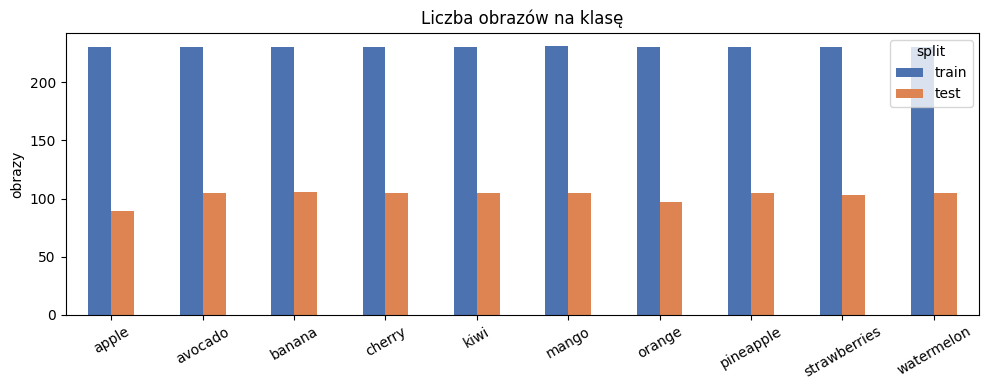

label,apple,avocado,banana,cherry,kiwi,mango,orange,pineapple,strawberries,watermelon
split,,,,,,,,,,
train,230,230,230,230,230,231,230,230,230,230
test,89,105,106,105,105,105,97,105,103,105


In [ ]:
# Wizualizacja ile obrazów na klasę
counts = pd.crosstab(both.label, both.split)[['train', 'test']]
ax = counts.plot.bar(figsize=(10, 4), color=['#4C72B0', '#DD8452'])
ax.set_title('Liczba obrazów na klasę'); ax.set_xlabel(''); ax.set_ylabel('obrazy')
plt.xticks(rotation=30); plt.tight_layout(); plt.show()
counts.T

Otwiera każdy plik (`Image.open` czyta tylko nagłówek, więc to jest szybkie) i zbiera szerokość, wysokość i tryb kolorów.
Wykresy pokazują rozrzut rozmiarów i proporcje szerokość/wysokość. Większość zdjęć jest poziomych (w/h > 1).

uszkodzone: 0 []
tryby: {'RGB': 3347, 'P': 27}
          w      h
min     1.0    1.0
mean  253.0  204.0
50%   259.0  194.0
max   453.0  363.0


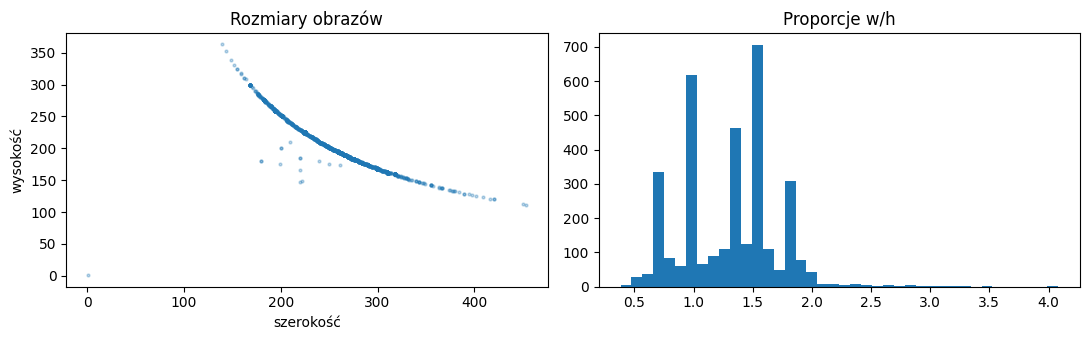

In [ ]:
# rozmiary, tryby kolorów, uszkodzone pliki

info, bad = [], []
for p in list(df_train.path) + list(df_test.path) + predict_files:
    try:
        with Image.open(p) as im:
            info.append((im.size[0], im.size[1], im.mode))
    except Exception as e:
        bad.append((p, e))
sz = pd.DataFrame(info, columns=['w', 'h', 'mode'])
print('uszkodzone:', len(bad), bad[:5])
print('tryby:', dict(Counter(sz['mode'])))
print(sz[['w', 'h']].describe().loc[['min', 'mean', '50%', 'max']].round(0))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].scatter(sz.w, sz.h, s=4, alpha=.3); axs[0].set_xlabel('szerokość'); axs[0].set_ylabel('wysokość'); axs[0].set_title('Rozmiary obrazów')
axs[1].hist(sz.w / sz.h, bins=40); axs[1].set_title('Proporcje w/h')
plt.tight_layout(); plt.show()

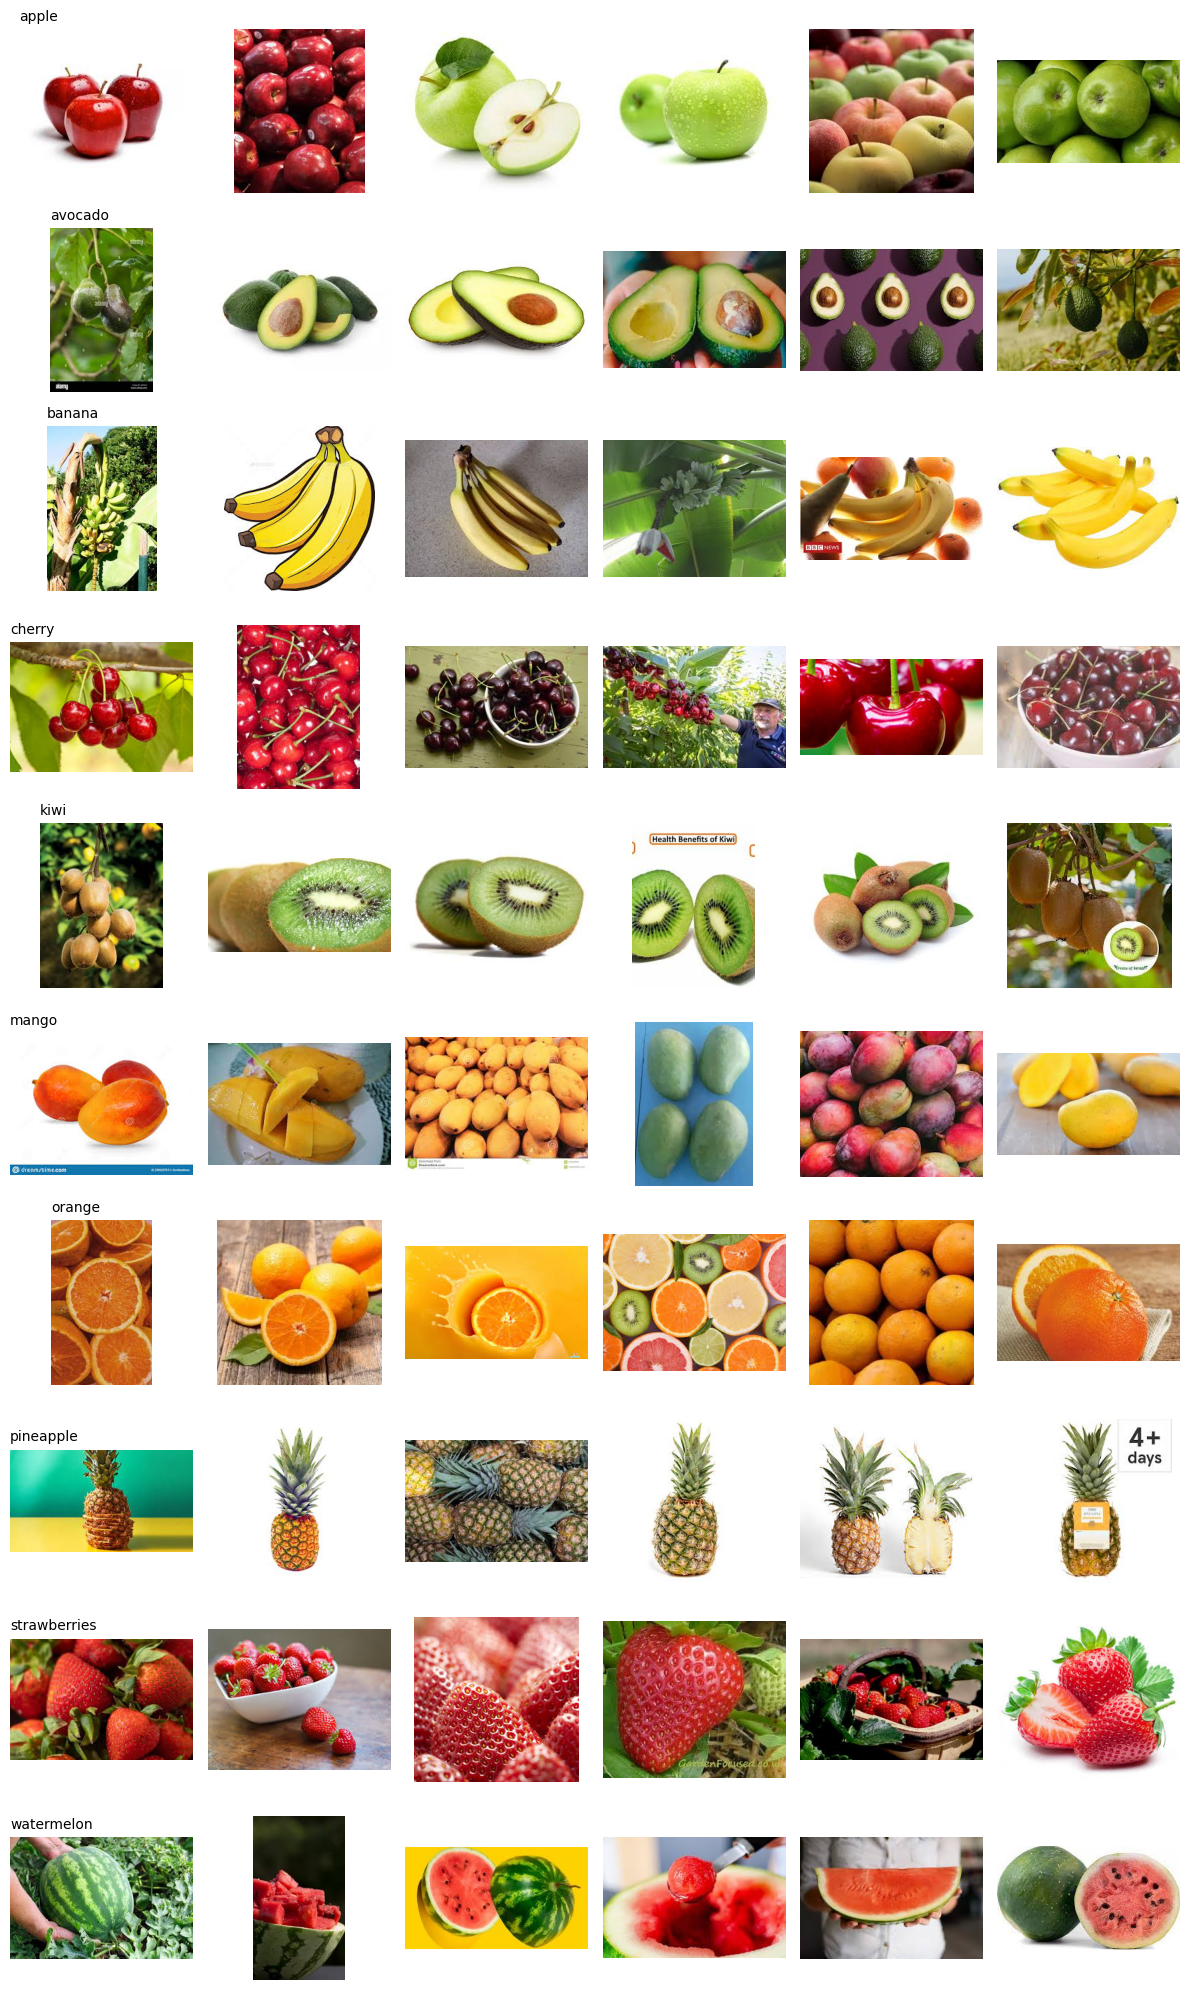

In [17]:
# przykładowe obrazy z każdej klasy
fig, axs = plt.subplots(len(CLASSES), 6, figsize=(12, 2 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    sample = df_train[df_train.label == c].sample(6, random_state=SEED)
    for k, p in enumerate(sample.path):
        axs[r, k].imshow(Image.open(p).convert('RGB')); axs[r, k].axis('off')
    axs[r, 0].set_title(c, loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 2. Dane w pamięci GPU + augmentacja na GPU
`train` dzielimy na część treningową i walidacyjną (15%). Walidacja służy do śledzenia wyników po każdej epoce i wyboru najlepszego checkpointu, `test` jest używany tylko raz — do końcowej oceny.

Każdy obraz jest dekodowany i skalowany do `IMG_SIZE` **raz**, Całość trafia na GPU jako `uint8` (1 bajt na piksel na kanał) (Używamy tego bo danych jest mało jakby było dużo więcej (<10G) było by to niemożliwe)
Normalizacja to mean/std z ImageNetu — takie, na jakich uczono pretrenowany model.
Dzięki temu w trakcie treningu nie ma żadnego wczytywania z dysku.


In [18]:
def load_img(p):
    img = Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)   # część plików jest w trybie 'P'
    return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)

def load_all(paths):
    with ThreadPoolExecutor(8) as ex:
        return torch.stack(list(ex.map(load_img, paths))).to(device)

def labels(df):
    return torch.tensor([CLS2IDX[l] for l in df.label], device=device)

t0 = time.time()
X_train, X_val, X_test, X_pred = load_all(df_tr.path), load_all(df_val.path), load_all(df_test.path), load_all(predict_files)
y_train, y_val, y_test = labels(df_tr), labels(df_val), labels(df_test)
size_mb = sum(X.numel() for X in (X_train, X_val, X_test, X_pred)) / 2**20
print(f'wczytano w {time.time()-t0:.0f}s | X_train {tuple(X_train.shape)} {X_train.dtype} | {size_mb:.0f} MB na {device}')

# mean/std ImageNet (pretrenowany model tego oczekuje)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

wczytano w 2s | X_train (1955, 3, 224, 224) torch.uint8 | 484 MB na cuda


## Augmentacja
To losowe zmiany zdjęć w trakcie treningu. Dzięki niej model co epokę widzi „trochę inne” zdjęcia i uczy się cech owocu, a nie zapamiętuje konkretnych plików. Wszystko liczy się na GPU, osobno dla każdego zdjęcia w batchu: (Macierz afiniczna to macierz reprezentująca przekształcenie afiniczne (np. obrót, skalowanie, pochylenie czy translację) w przestrzeni geometrycznej.)
| przekształcenie | zakres | jak |
| obrót | ±15° | macierz afiniczna |
| przybliżenie (zoom) | wycinek 70–100% powierzchni | skala = √(0.7…1.0) w macierzy afinicznej |
| przesunięcie | tak, żeby wycinek nie wyszedł poza obraz | `tx, ty ∈ ±(1 − zoom)` |
| odbicie poziome | 50% szans | znak −1 w pierwszej kolumnie macierzy |
| jasność | ×0.8–1.2 | mnożenie |
| kontrast | ±20% | rozciągnięcie wokół średniej obrazu |
| nasycenie | ±20% | rozciągnięcie wokół wersji szarej |


In [19]:
def augment(x):
    """Na GPU, osobne losowanie dla każdego obrazu w batchu:
    obrót ±15°, zoom/przesunięcie (jak RandomResizedCrop 0.7–1), odbicie poziome, jasność/kontrast/nasycenie ±20%."""
    B = len(x)
    rnd = lambda lo, hi: torch.empty(B, device=x.device).uniform_(lo, hi)
    ang, zoom = rnd(-15, 15).deg2rad(), rnd(0.7, 1.0).sqrt()
    flip = torch.where(torch.rand(B, device=x.device) < 0.5, -1.0, 1.0)
    tx, ty = rnd(-1, 1) * (1 - zoom), rnd(-1, 1) * (1 - zoom)
    cos, sin = ang.cos() * zoom, ang.sin() * zoom
    theta = torch.stack([torch.stack([cos * flip, -sin, tx], 1),
                         torch.stack([sin * flip,  cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)

    v = lambda t: t.view(B, 1, 1, 1)
    x = x * v(rnd(0.8, 1.2))                                                  # jasność
    m = x.mean((1, 2, 3), keepdim=True); x = (x - m) * v(rnd(0.8, 1.2)) + m   # kontrast
    g = x.mean(1, keepdim=True);         x = (x - g) * v(rnd(0.8, 1.2)) + g   # nasycenie
    return x.clamp(0, 1)

def prep(x_u8, train=False):
    x = x_u8.float() / 255
    if train:
        x = augment(x)
    return (x - MEAN) / STD

def batches(X, y=None, train=False):
    idx = torch.randperm(len(X), device=X.device) if train else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), BATCH):
        j = idx[i:i + BATCH]
        yield prep(X[j], train), (y[j] if y is not None else None)

xb, yb = next(batches(X_train, y_train, train=True))
print('batch:', tuple(xb.shape), xb.dtype, xb.device, '| labels:', yb[:10].tolist())
print(f'po normalizacji: mean={xb.mean():.3f} std={xb.std():.3f}')

batch: (64, 3, 224, 224) torch.float32 cuda:0 | labels: [2, 0, 2, 7, 1, 2, 5, 2, 5, 4]
po normalizacji: mean=0.357 std=1.338


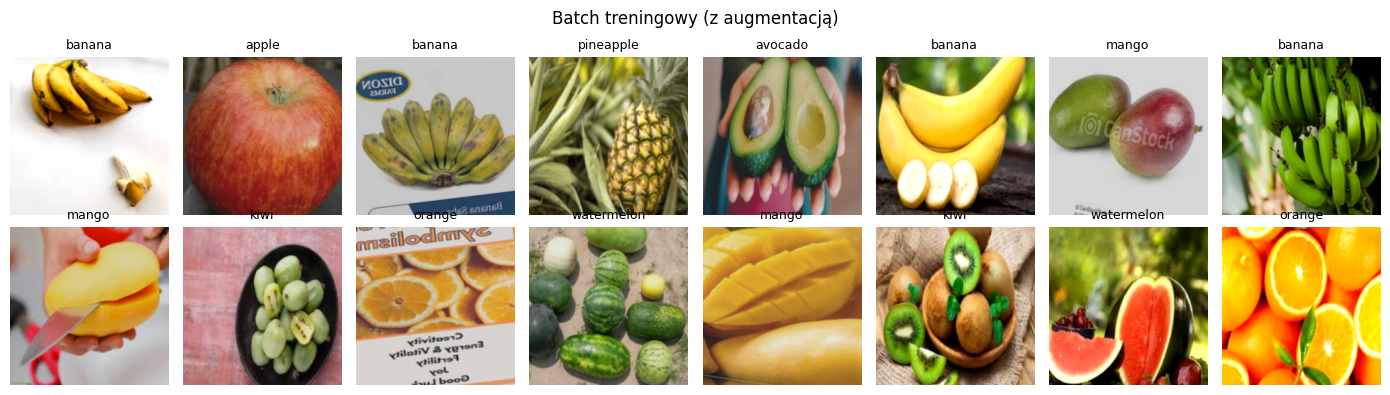

In [ ]:
# podgląd batcha po augmentacji (odwrócona normalizacja) (Dane po krzekształceniach)
def denorm(x):
    return (x * STD + MEAN).clamp(0, 1).cpu()

fig, axs = plt.subplots(2, 8, figsize=(14, 4))
for ax, x, y in zip(axs.flat, denorm(xb[:16]), yb[:16].tolist()):
    ax.imshow(x.permute(1, 2, 0)); ax.set_title(CLASSES[y], fontsize=9); ax.axis('off')
plt.suptitle('Batch treningowy (z augmentacją)'); plt.tight_layout(); plt.show()

## 3. Model

Wczytuje EfficientNet-B0 (Model który dotrenowujemy) z wagami ImageNet. Przy pierwszym uruchomieniu pobiera plik 20,5 MB do `~/.cache/torch/hub/checkpoints/`.
- **Podmienia głowę (classifier).** Oryginalnie to `Dropout(0.2) → Linear(1280 → 1000)`, a teraz `Dropout(0.3) → Linear(1280 → 10)`.
  - `Dropout(0.3)` w trakcie treningu losowo zeruje 30% z 1280 cech, przez co model nie może polegać na kilku wybranych cechach. To regularyzacja.
  - `Linear(1280 → 10)` ma 1280·10 + 10 = **12 810** parametrów. Tylko te startują od zera.
- Łącznie model ma **4 020 358 parametrów**.
- Kontrola kształtów: `features: (2, 1280, 7, 7)` i `logits: (2, 10)`, czyli zgodnie z oczekiwaniami.


In [21]:
model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.classifier[1].in_features, len(CLASSES)))
model = model.to(device)
print(model.classifier)
print(f'parametry: {sum(p.numel() for p in model.parameters()):,}  (głowa: {sum(p.numel() for p in model.classifier.parameters()):,})')

# kontrola kształtów
model.eval()
with torch.no_grad():
    print('features:', tuple(model.features(xb[:2]).shape), '| logits:', tuple(model(xb[:2]).shape))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 25.9MB/s]


Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=10, bias=True)
)
parametry: 4,020,358  (głowa: 12,810)
features: (2, 1280, 7, 7) | logits: (2, 10)


## 4. Trening

- ` *1 ` Cross-entropy to standardowa strata do klasyfikacji: kara jest tym większa, im mniejsze prawdopodobieństwo model daje poprawnej klasie.
**Label smoothing 0.1** oznacza, że zamiast celu „100% jabłko, 0% reszta” model dostaje cel „91% jabłko, po 1% każda z 9 pozostałych klas”. Dzięki temu nie dąży do absurdalnej pewności, a to pomaga przy etykietach z internetu, które bywają błędne lub niejednoznaczne.
- ` *2 ` Optymalizator w PyTorch to algorytm, który kieruje nauką sieci neuronowej. Jego zadaniem jest zmienianie wag (parametrów) modelu w taki sposób, aby sieć popełniała jak najmniej błędów. AdamW (ang. Adam with Decoupled Weight Decay) to ulepszona wersja optymalizatora Adam.
- ` *3 ` Przez pierwsze 20% treningu LR rośnie od małej wartości do maksimum (taka rozgrzewka chroni pretrenowane wagi na starcie) a potem łagodnie spada prawie do zera (kształt cosinusa)
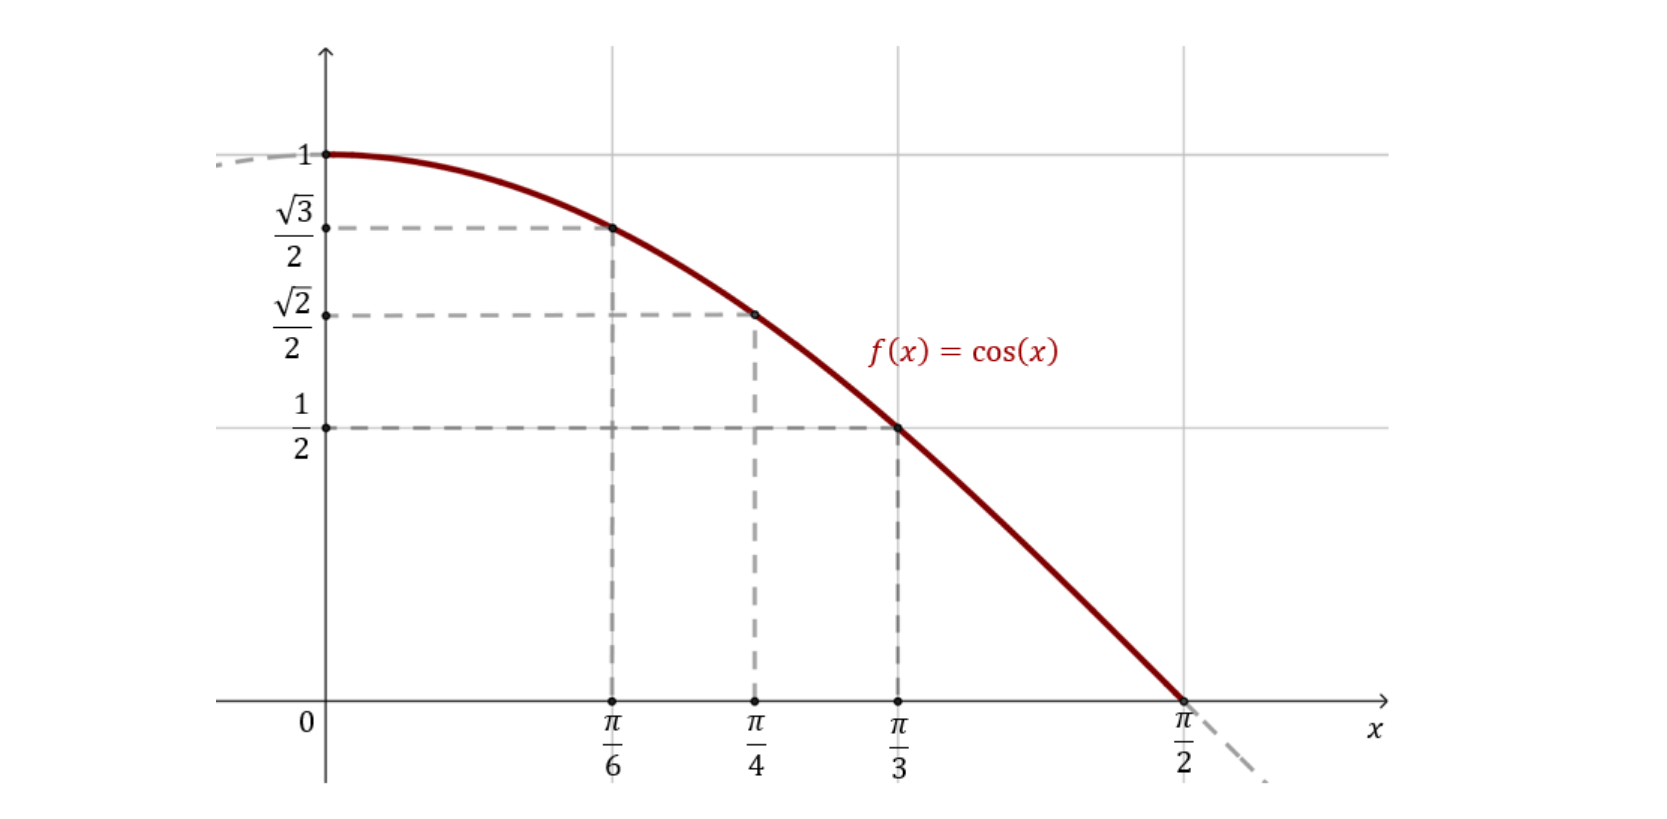

Jak to czytać:
- **Epoka 1 trwa 20 s, kolejne po 2 s.** Za pierwszym razem cuDNN dobiera najszybsze algorytmy konwolucji, a CUDA kompiluje i ładuje kernele. To jednorazowy koszt.
- **W epoce 1 accuracy na train (0.21) jest niższa niż na walidacji (0.58).** Train accuracy liczymy *w trakcie* epoki, kiedy głowa dopiero się uczy od losowego startu. Do tego w treningu działa augmentacja i dropout. Walidacja jest liczona *po* epoce, na już douczonym modelu i bez utrudnień.
- **Po 3 epokach mamy 95,7% na walidacji.** Dalej wynik rośnie już tylko lekko (do 97,4%).
- **Train acc 99,7% a val acc 97,4%** to niewielka różnica. Model trochę lepiej zna dane treningowe, ale nie przeucza się w groźny sposób, bo val loss nie rośnie i spada aż do końca.

In [ ]:

criterion = nn.CrossEntropyLoss(label_smoothing=0.1) # *1
optimizer = torch.optim.AdamW([ # *2
    {'params': model.features.parameters(),   'lr': LR / 10},   # pretrenowany backbone — małe kroki
    {'params': model.classifier.parameters(), 'lr': LR},        # nowa głowa
], weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[LR / 10, LR], epochs=EPOCHS, # *3
                                                steps_per_epoch=math.ceil(len(X_train) / BATCH), pct_start=0.2)
# mixed precision: ~2× szybciej i mniej pamięci na GPU 
use_amp = device.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_epoch(X, Y, train):
    """
    `run_epoch(X, Y, train)` przechodzi raz przez dane. W trybie treningu robi augmentację, liczy gradienty i aktualizuje wagi. W trybie oceny wyłącza dropout, a BatchNorm używa zapamiętanych statystyk zamiast statystyk z batcha.
    - Strata i trafienia są sumowane na GPU, a `.item()` (synchronizacja GPU→CPU) jest wywoływane raz na epokę, a nie co batch, żeby nie spowalniać.
    - **Najlepszy checkpoint:** po każdej epoce sprawdzamy accuracy na walidacji. Jeśli jest najlepsza do tej pory, kopiujemy wagi (`copy.deepcopy(model.state_dict())`) i w logu pojawia się `*`. Po treningu wczytujemy najlepsze wagi.
    - Model zapisuje się do `fruit_effnet.pt` razem z listą klas, mean/std i rozmiarem obrazu. To wszystko, czego trzeba, żeby użyć go później w innym skrypcie.
    """
    model.train(train)
    tot_loss, correct = torch.zeros((), device=device), torch.zeros((), device=device)
    with torch.set_grad_enabled(train):
        for x, y in batches(X, Y, train):
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
            tot_loss += loss.detach().float() * len(y); correct += (out.argmax(1) == y).sum()
    return tot_loss.item() / len(X), correct.item() / len(X)   # .item() raz na epokę, nie co batch

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'lr': []}
best_acc, best_ep, best_state = -1, 0, None
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    history['lr'].append(optimizer.param_groups[1]['lr'])
    tl, ta = run_epoch(X_train, y_train, True)
    vl, va = run_epoch(X_val, y_val, False)
    for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tl, ta, vl, va]):
        history[k].append(v)
    mark = ''
    if va > best_acc:
        best_acc, best_ep, best_state, mark = va, ep, copy.deepcopy(model.state_dict()), '  *'
    print(f'ep {ep:2d}/{EPOCHS} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s{mark}')

model.load_state_dict(best_state)
print(f'najlepsza epoka: {best_ep} (val acc {best_acc:.3f})')
torch.save({'arch': 'efficientnet_b0', 'state_dict': model.state_dict(), 'classes': CLASSES,
            'mean': MEAN.flatten().tolist(), 'std': STD.flatten().tolist(), 'img_size': IMG_SIZE}, 'fruit_effnet.pt')
print('zapisano fruit_effnet.pt')

ep  1/12 | train loss 2.232 acc 0.212 | val loss 1.960 acc 0.578 | 20s  *
ep  2/12 | train loss 1.541 acc 0.738 | val loss 0.880 acc 0.916 | 2s  *
ep  3/12 | train loss 0.811 acc 0.916 | val loss 0.697 acc 0.957 | 2s  *
ep  4/12 | train loss 0.671 acc 0.962 | val loss 0.667 acc 0.957 | 2s
ep  5/12 | train loss 0.631 acc 0.975 | val loss 0.641 acc 0.965 | 2s  *
ep  6/12 | train loss 0.601 acc 0.987 | val loss 0.634 acc 0.965 | 2s
ep  7/12 | train loss 0.581 acc 0.994 | val loss 0.631 acc 0.965 | 2s
ep  8/12 | train loss 0.578 acc 0.993 | val loss 0.626 acc 0.962 | 2s
ep  9/12 | train loss 0.571 acc 0.995 | val loss 0.625 acc 0.965 | 2s
ep 10/12 | train loss 0.571 acc 0.994 | val loss 0.622 acc 0.968 | 2s  *
ep 11/12 | train loss 0.569 acc 0.996 | val loss 0.624 acc 0.965 | 2s
ep 12/12 | train loss 0.566 acc 0.997 | val loss 0.623 acc 0.974 | 2s  *
najlepsza epoka: 12 (val acc 0.974)
zapisano fruit_effnet.pt


## 5. Podsumowanie treningu

Trzy wykresy: strata (train/val), accuracy (train/val, przerywana linia oznacza najlepszą epokę) i learning rate głowy w czasie. Na wykresie LR widać kształt OneCycle: szybki wzrost przez pierwsze ~2,5 epoki, potem łagodny spadek.

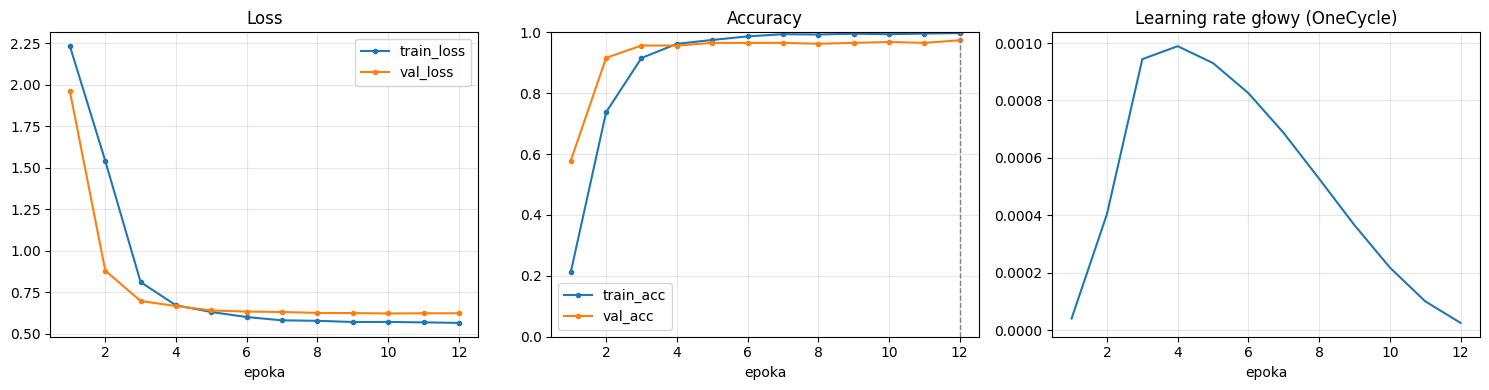

,train_loss,val_loss,train_acc,val_acc,lr
8,0.578,0.626,0.993,0.962,0.001
9,0.571,0.625,0.995,0.965,0.000
10,0.571,0.622,0.994,0.968,0.000
11,0.569,0.624,0.996,0.965,0.000
12,0.566,0.623,0.997,0.974,0.000


In [23]:
h = pd.DataFrame(history); h.index += 1
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
h[['train_loss', 'val_loss']].plot(ax=axs[0], marker='o', ms=3, title='Loss')
h[['train_acc', 'val_acc']].plot(ax=axs[1], marker='o', ms=3, title='Accuracy')
axs[1].set_ylim(0, 1); axs[1].axvline(best_ep, color='gray', ls='--', lw=1)
h['lr'].plot(ax=axs[2], title='Learning rate głowy (OneCycle)')
for ax in axs: ax.set_xlabel('epoka'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
h.round(3).tail()

## 6. Ewaluacja na zbiorze testowym
Model z najlepszej epoki (wg walidacji). Predykcje z TTA: średnia z oryginału i odbicia poziomego.
- `classification_report` podaje dla każdej klasy:
  - **precision**: z tego, co model nazwał np. „mango”, jaki odsetek naprawdę jest mango,
  - **recall**: z prawdziwych mango, jaki odsetek model znalazł,
  - **f1-score**: średnia harmoniczna obu,
  - **support**: liczba zdjęć danej klasy w teście.

In [24]:
@torch.no_grad()
def predict(X, tta=True):
    model.eval()
    out = []
    for x, _ in batches(X):
        p = F.softmax(model(x), 1)
        if tta:
            p = (p + F.softmax(model(x.flip(3)), 1)) / 2
        out.append(p)
    return torch.cat(out).cpu().numpy()

test_probs, test_y = predict(X_test), y_test.cpu().numpy()
test_pred = test_probs.argmax(1)
print(f'TEST accuracy: {(test_pred == test_y).mean():.3f}  (bez TTA: {(predict(X_test, tta=False).argmax(1) == test_y).mean():.3f}, n={len(test_y)})\n')
print(classification_report(test_y, test_pred, target_names=CLASSES, digits=3))

TEST accuracy: 0.936  (bez TTA: 0.938, n=1025)

              precision    recall  f1-score   support

       apple      0.891     0.921     0.906        89
     avocado      0.912     0.981     0.945       105
      banana      0.971     0.953     0.962       106
      cherry      0.881     0.914     0.897       105
        kiwi      0.990     0.981     0.986       105
       mango      0.938     0.857     0.896       105
      orange      0.922     0.979     0.950        97
   pineapple      0.990     0.981     0.986       105
strawberries      0.926     0.854     0.889       103
  watermelon      0.933     0.933     0.933       105

    accuracy                          0.936      1025
   macro avg      0.935     0.936     0.935      1025
weighted avg      0.936     0.936     0.935      1025



### Macierz pomyłek 
(Standard przy ocenie poprawności działania modelu (tym przekontna bliżej do 1 to lepiej))
(confusion matrix(- bardziej popularne po ang))
Wiersze to prawdziwa klasa, kolumny to przewidywanie. Na przekątnej są trafienia, a poza nią pomyłki. Lewy wykres pokazuje liczby, prawy jest znormalizowany per wiersz (przekątna = recall danej klasy).

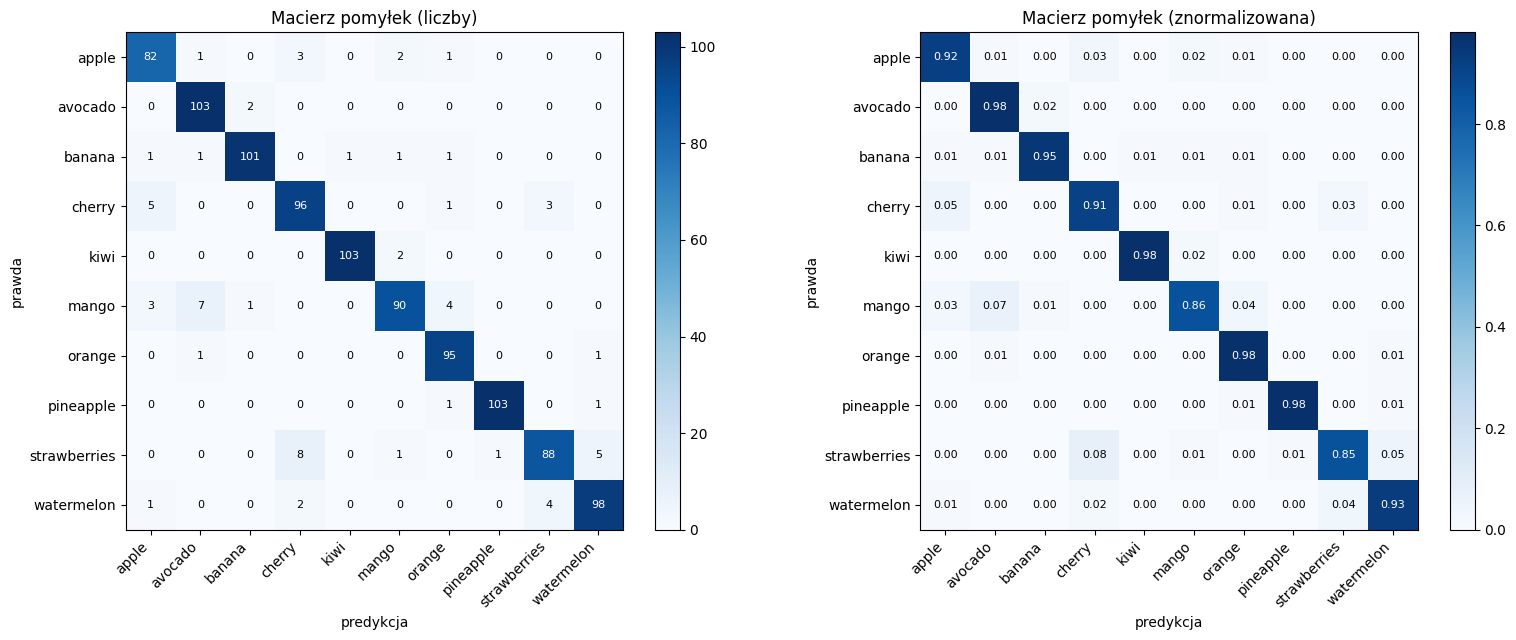

In [25]:
cm = confusion_matrix(test_y, test_pred)
cm_n = cm / cm.sum(1, keepdims=True)
fig, axs = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, m, title, fmt in [(axs[0], cm, 'Macierz pomyłek (liczby)', 'd'), (axs[1], cm_n, 'Macierz pomyłek (znormalizowana)', '.2f')]:
    im = ax.imshow(m, cmap='Blues'); fig.colorbar(im, ax=ax, fraction=.046)
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel('predykcja'); ax.set_ylabel('prawda'); ax.set_title(title)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, format(m[i, j], fmt), ha='center', va='center', fontsize=8,
                    color='white' if m[i, j] > m.max() / 2 else 'black')
plt.tight_layout(); plt.show()

## Accuracy per klasa i pewność modelu
- Lewy wykres: accuracy dla każdej klasy, od najgorszej. Słupki poniżej 0.8 byłyby czerwone, ale tu żadnego takiego nie ma.
- Prawy wykres: histogram „pewności” (najwyższego prawdopodobieństwa) osobno dla trafień i pomyłek. Wnioski w sekcji 4.

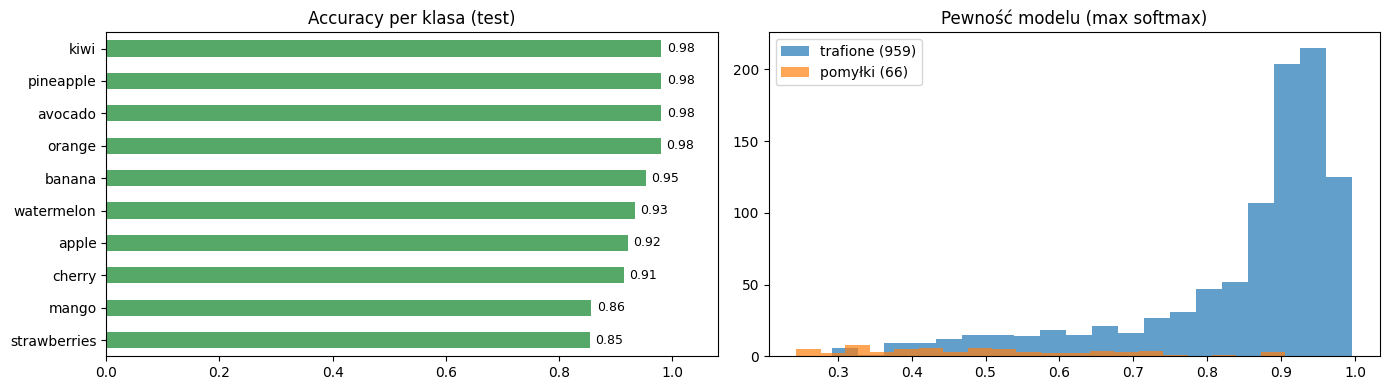

In [26]:
# accuracy per klasa + rozkład pewności dla trafionych / pomylonych
per_cls = pd.Series(cm.diagonal() / cm.sum(1), index=CLASSES).sort_values()
conf = test_probs.max(1); ok = test_pred == test_y
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
per_cls.plot.barh(ax=axs[0], color=['#C44E52' if v < .8 else '#55A868' for v in per_cls])
axs[0].set_xlim(0, 1.08); axs[0].set_title('Accuracy per klasa (test)')
for i, v in enumerate(per_cls): axs[0].text(v + .01, i, f'{v:.2f}', va='center', fontsize=9)
axs[1].hist(conf[ok], bins=20, alpha=.7, label=f'trafione ({ok.sum()})')
axs[1].hist(conf[~ok], bins=20, alpha=.7, label=f'pomyłki ({(~ok).sum()})')
axs[1].set_title('Pewność modelu (max softmax)'); axs[1].legend()
plt.tight_layout(); plt.show()

## Najbardziej pewne pomyłki
(Na czesci zdjęć są 2 owoce, jakiś facet/kobieta i banano-kiwi żeby uzyskać lepszy wynik pewnie trzeba by je było usunąć z bazy zdjęć)
12 zdjęć, przy których model się pomylił, a był najbardziej pewny swojej odpowiedzi. To najlepsze miejsce do szukania błędnych etykiet i nietypowych zdjęć w danych.

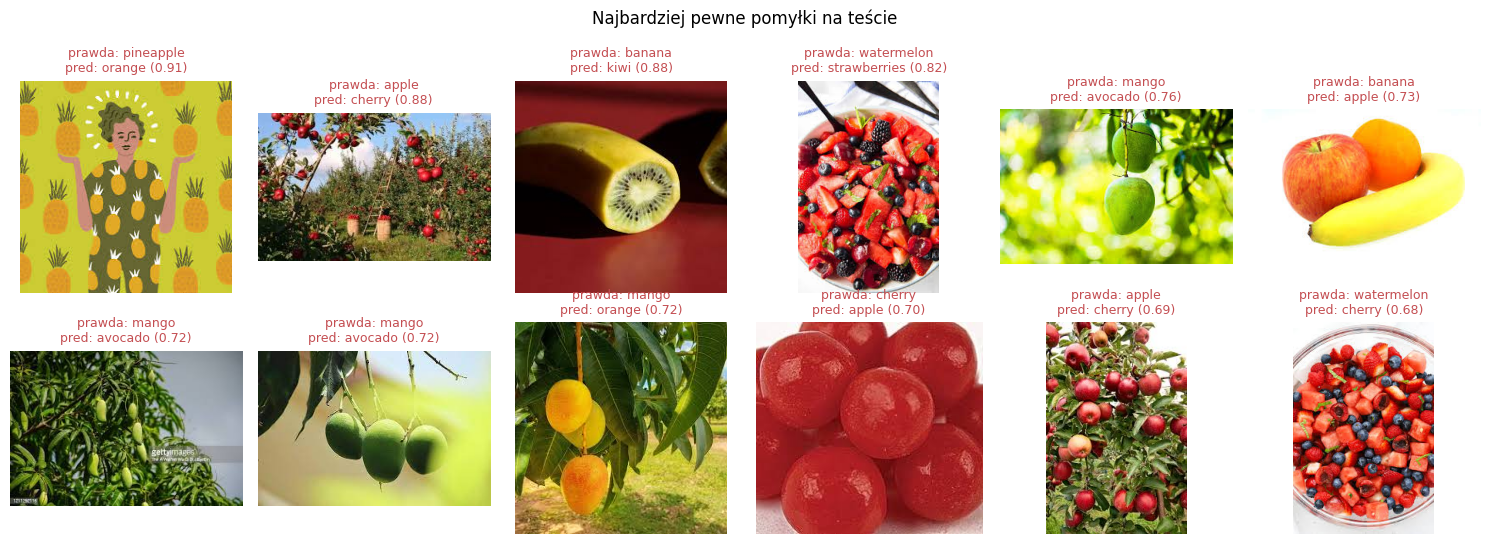

In [27]:
# najbardziej pewne pomyłki
wrong = np.flatnonzero(~ok)
wrong = wrong[np.argsort(-conf[wrong])][:12]
if len(wrong):
    fig, axs = plt.subplots(2, 6, figsize=(15, 5.5))
    for ax in axs.flat: ax.axis('off')
    for ax, i in zip(axs.flat, wrong):
        ax.imshow(Image.open(df_test.path.iloc[i]).convert('RGB'))
        ax.set_title(f'prawda: {CLASSES[test_y[i]]}\npred: {CLASSES[test_pred[i]]} ({conf[i]:.2f})', fontsize=9, color='#C44E52')
    plt.suptitle('Najbardziej pewne pomyłki na teście'); plt.tight_layout(); plt.show()

## 7. Predykcja na `owoce/predict`

In [28]:
pred_probs, pred_paths = predict(X_pred), predict_files
top = pred_probs.argmax(1)
results = pd.DataFrame({'plik': [p.name for p in pred_paths],
                        'predykcja': [CLASSES[i] for i in top],
                        'pewność': pred_probs.max(1).round(3)})
results.to_csv('predykcje.csv', index=False)
print(results['predykcja'].value_counts().to_string())
results.sort_values('pewność').head(10)

predykcja
watermelon      6
apple           5
cherry          5
kiwi            5
pineapple       5
strawberries    5
orange          5
avocado         4
banana          4
mango           4


,plik,predykcja,pewność
47,img_421.jpeg,orange,0.332
36,img_21.jpeg,watermelon,0.359
16,4.jpeg,apple,0.474
4,0122.jpeg,watermelon,0.506
23,9.jpeg,cherry,0.630
14,33.jpeg,pineapple,0.664
22,77.jpeg,pineapple,0.734
10,202.jpeg,kiwi,0.806
29,f7.jpeg,strawberries,0.811
1,00.jpeg,cherry,0.821


## Predykcja na owoce/predict 
Dla 48 zdjęć bez etykiet przewiduje klasę i pewność, zapisuje wynik do `predykcje.csv` i pokazuje 10 najmniej pewnych przypadków.
(Predict to ok 5 zdjęć z każdej kategori bez etykiety(dla train i test etykieta jest))


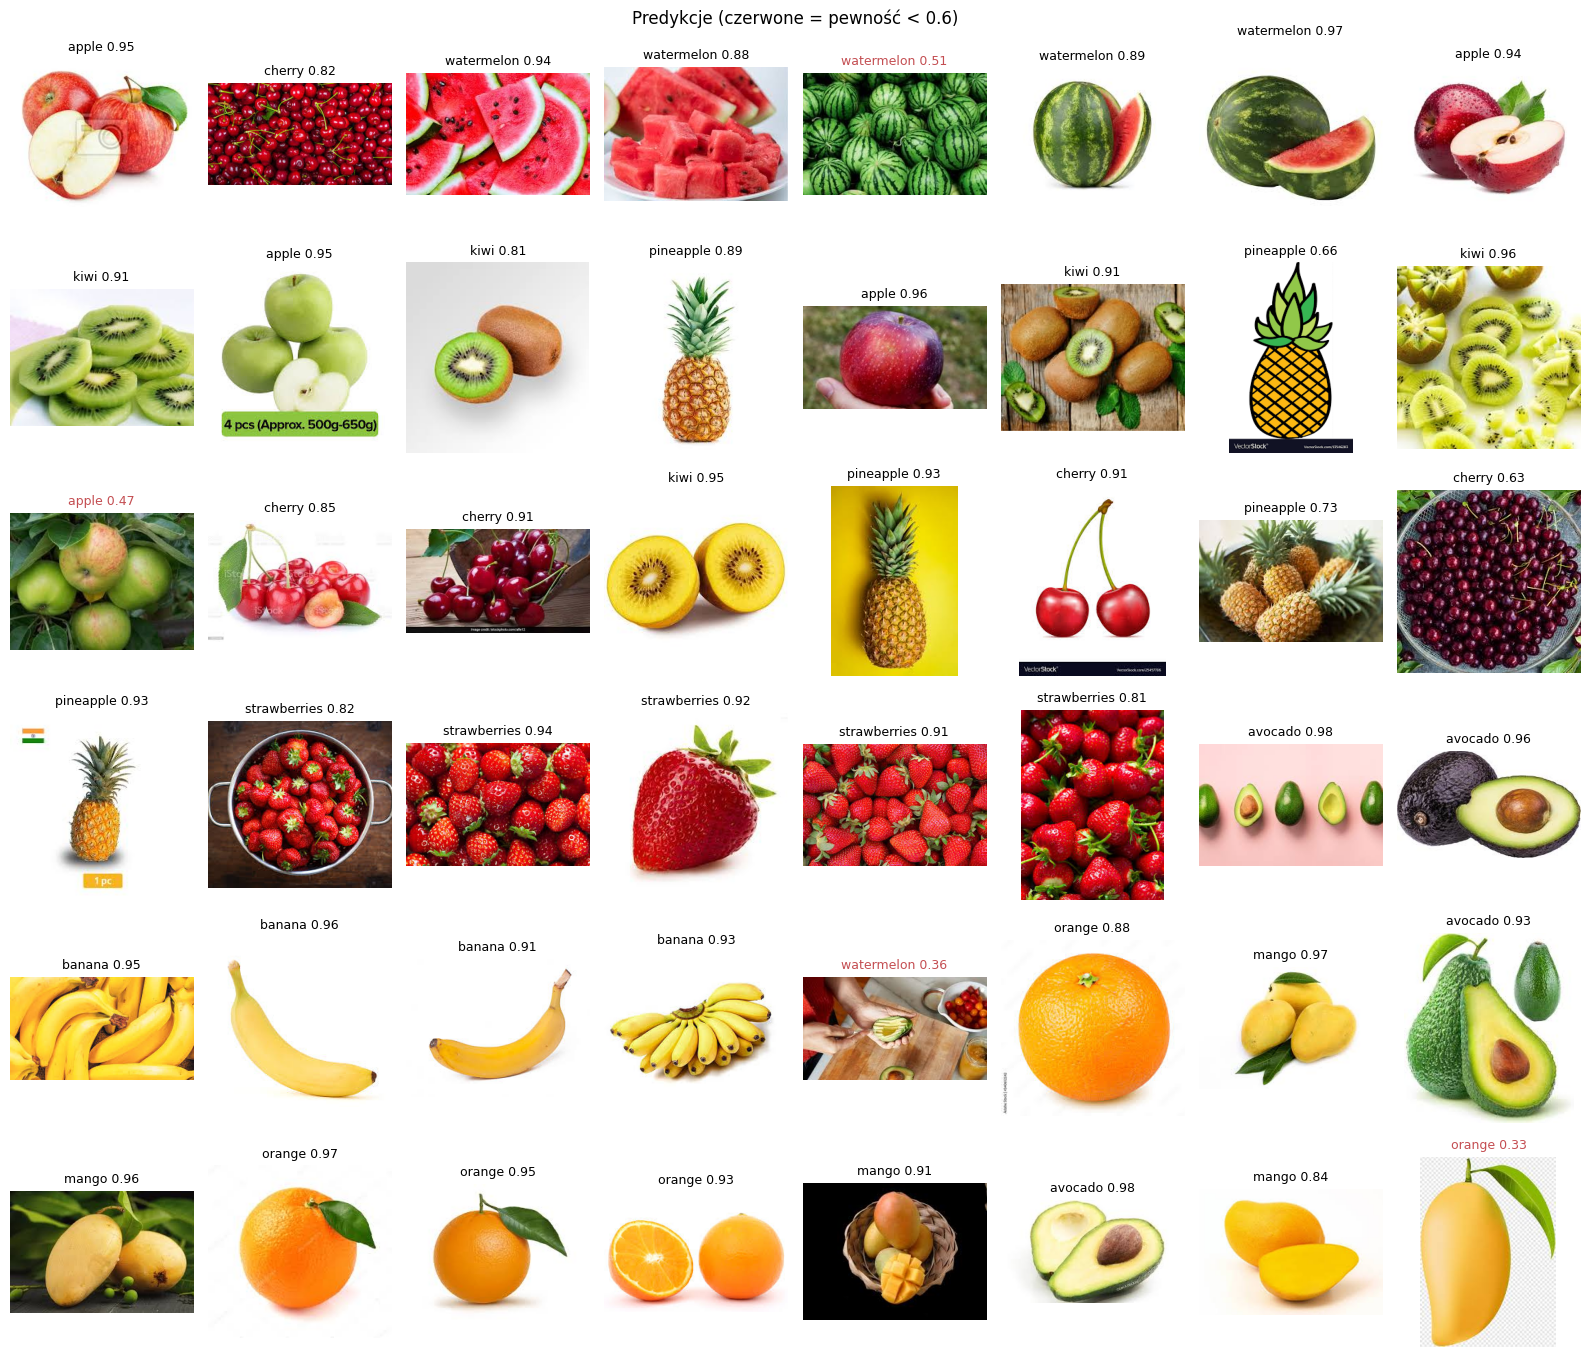

In [ ]:
n = len(pred_paths); cols = 8; rows = int(np.ceil(n / cols))
fig, axs = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.3))
for ax in axs.flat: ax.axis('off')
for ax, p, i, c in zip(axs.flat, pred_paths, top, pred_probs.max(1)):
    ax.imshow(Image.open(p).convert('RGB'))
    ax.set_title(f'{CLASSES[i]} {c:.2f}', fontsize=9, color='black' if c >= .6 else '#C44E52')
plt.suptitle('Predykcje (czerwone = pewność < 0.6)'); plt.tight_layout(); plt.show()

### Podsumowanie
Jest dobrze, przez czyczczenie bazy zdjęć z niejednoznacznych i dziwnych danych i zabawę parametrami można poprawic wynik, ale na tak małej bazie ten jest akceptowalny(dla test które ni brały udziału w uczeniu TEST accuracy:  `~0.936`) 